In [1]:
import yfinance as yf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
# === 1. Parameters ===
#tickers = ["AAPL", "MSFT", "NVDA", "AMZN", "META", "GOOGL", "TSLA"]
tickers = ["WBD", "PARA", "APA", "WBA", "PCG", "VTRS", "COTY"]
equal_weight = 1 / len(tickers)

In [3]:
# === 2. Download Adjusted Close Data ===
data = yf.download(tickers, period="10y", interval="1d", auto_adjust=False)["Adj Close"]
data = data.dropna()  # Drop rows with missing data


[*********************100%***********************]  7 of 7 completed


In [4]:
# resample to obtain yearly data
data_resampled = data.resample('Y').last()

In [5]:
# === 3. Normalize prices (so year 0 = 1) ===
normalized = data_resampled / data_resampled.iloc[0]

In [6]:
# === 4. BAH (Buy-And-Hold) Portfolio ===
# Fixed allocation from t=0 (just scales each column by 1/7 and sums)
V0 = 10_000
bah_portfolio = (normalized * equal_weight).sum(axis=1) * V0

In [7]:
# === 5. Constantly Rebalanced Portfolio ===
# Compute yearly returns
yearly_returns = data_resampled.pct_change().dropna()
# Initialise list of rebalanced portfolio values
rebalanced_values = [10_000]  # <- Start at 10,000

# Rebalance to equal weights yearly
for returns in yearly_returns.itertuples(index=False):
    portfolio_value = rebalanced_values[-1]
    step_growth = sum(equal_weight * r for r in returns)
    rebalanced_values.append(portfolio_value * (1 + step_growth))

rebalanced_portfolio = pd.Series(rebalanced_values, index = data_resampled.index)

In [8]:
# === 6. Create Series of Updated Theta Values ===
theta = normalized.shift(1).div(normalized.shift(1).sum(axis=1), axis=0)
# .shift(1) will create a first row of NaN values but this is fine, can be excluded later for visualisation purposes

In [9]:
# # === 7. Constantly Rebalanced Portfolio with Transaction Costs ===
# rebalanced_values = [10_000]
# transaction_costs = [0]  # Initialize transaction costs

# prev_weights = np.array([equal_weight] * len(tickers))  # Initial equal weights

# for i, returns in enumerate(yearly_returns.itertuples(index=False)):
#     portfolio_value = rebalanced_values[-1]
#     current_weights = np.array([equal_weight] * len(tickers))  # Rebalance to equal weights
    
#     # Calculate capital allocation changes Δᵢₜ
#     price_ratio = data_resampled.iloc[i + 1] / data_resampled.iloc[i]  # Xᵢ(t) / Xᵢ(t-1)
#     capital_prev = prev_weights * portfolio_value
#     capital_prev_adjusted = capital_prev * price_ratio.values
#     capital_prev_adjusted /= capital_prev_adjusted.sum()  # Normalize to get new weights
#     capital_prev_adjusted *= portfolio_value

#     capital_new = current_weights * portfolio_value
#     delta = capital_new - capital_prev_adjusted

#     # Compute transaction cost
#     cost = 0
#     for change in delta:
#         if abs(change) > 0:
#             cost += max(0.001 * abs(change), 1)
    
#     # Update portfolio value
#     step_growth = sum(current_weights * returns)
#     new_value = (portfolio_value - cost) * (1 + step_growth)

#     # Append new values
#     rebalanced_values.append(new_value)
#     transaction_costs.append(transaction_costs[-1] + cost)
    
#     # Update previous weights
#     prev_weights = current_weights

# # Create Series
# rebalanced_portfolio_net = pd.Series(rebalanced_values, index=data.index[:len(rebalanced_values)])
# transaction_cost_series = pd.Series(transaction_costs, index=data.index[:len(transaction_costs)])


In [10]:
# === 7. Constantly Rebalanced Portfolio with Transaction Costs using Theta Values ===

transaction_costs = [0]
rebalanced_values = [10_000]

# Loop starts at 1 because theta is shifted by 1
for t in range(1, len(data_resampled)):
    V_t_minus_1 = rebalanced_values[-1]
    
    # Price ratio for each stock: Xᵢ(t) / Xᵢ(t-1)
    price_ratio = data_resampled.iloc[t] / data_resampled.iloc[t - 1]

    # θᵢₜ = equal weights for rebalancing
    theta_t = np.array([equal_weight] * len(tickers))
    #theta_t = theta.iloc[t]

    # θᵢₜ₋₁ from the precomputed Series (weights from previous time)
    theta_t_minus_1 = theta.iloc[t]

    # Δᵢₜ = θᵢₜ * Vₜ - θᵢₜ₋₁ * Vₜ₋₁ * (Xᵢ(t) / Xᵢ(t-1))
    capital_now = theta_t * V_t_minus_1
    capital_prev = theta_t_minus_1 * V_t_minus_1 * price_ratio.values
    delta = capital_now - capital_prev

    # Apply transaction cost formula
    cost = sum(max(0.001 * abs(d), 1) for d in delta if abs(d) > 0)

    # Apply returns after subtracting transaction costs
    step_return = yearly_returns.iloc[t - 1]
    growth = sum(theta_t * step_return)
    V_t = (V_t_minus_1 - cost) * (1 + growth)

    transaction_costs.append(transaction_costs[-1] + cost)
    rebalanced_values.append(V_t)

rebalanced_portfolio_net = pd.Series(rebalanced_values, index=data_resampled.index[:len(rebalanced_values)])
transaction_cost_series = pd.Series(transaction_costs, index=data_resampled.index[:len(transaction_costs)])

In [11]:
# === 8. Market Index ===
market_index = (data_resampled.sum(axis=1) / data_resampled.sum(axis=1).iloc[0]) * V0
print(market_index.head())

Date
2015-12-31    10000.000000
2016-12-31    10945.461181
2017-12-31    16192.206903
2018-12-31    15639.943113
2019-12-31    23246.465984
Freq: A-DEC, dtype: float64


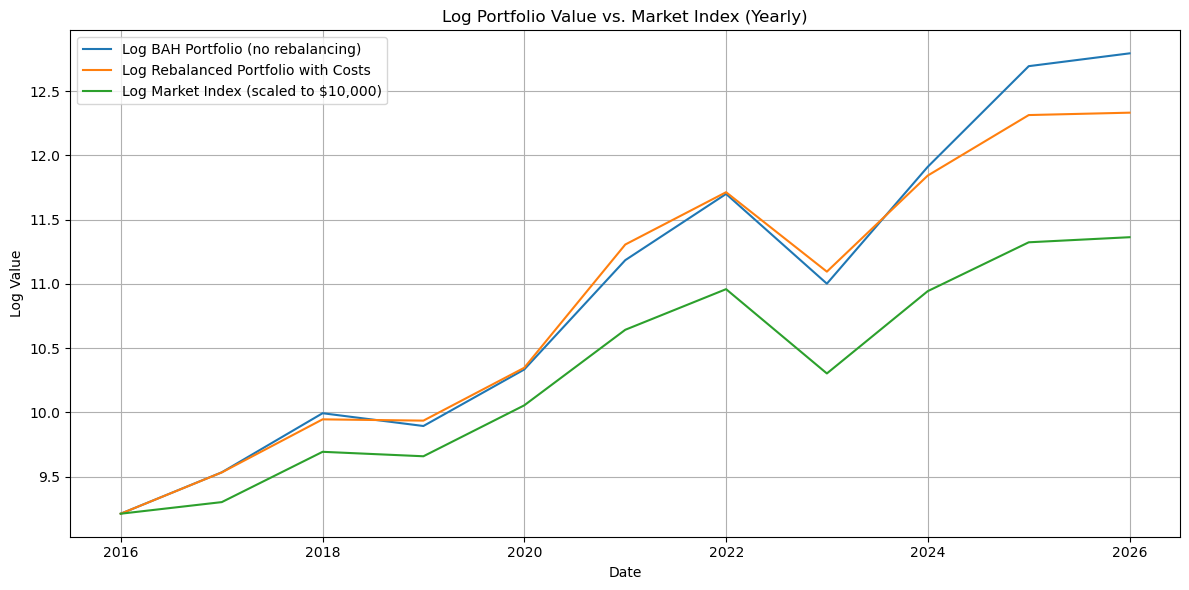

In [12]:
# === 9. Plot all three log values ===
plt.figure(figsize=(12, 6))
plt.plot(np.log(bah_portfolio), label="Log BAH Portfolio (no rebalancing)")
plt.plot(np.log(rebalanced_portfolio_net), label="Log Rebalanced Portfolio with Costs")
plt.plot(np.log(market_index), label="Log Market Index (scaled to $10,000)")
plt.title("Log Portfolio Value vs. Market Index (Yearly)")
plt.xlabel("Date")
plt.ylabel("Log Value")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

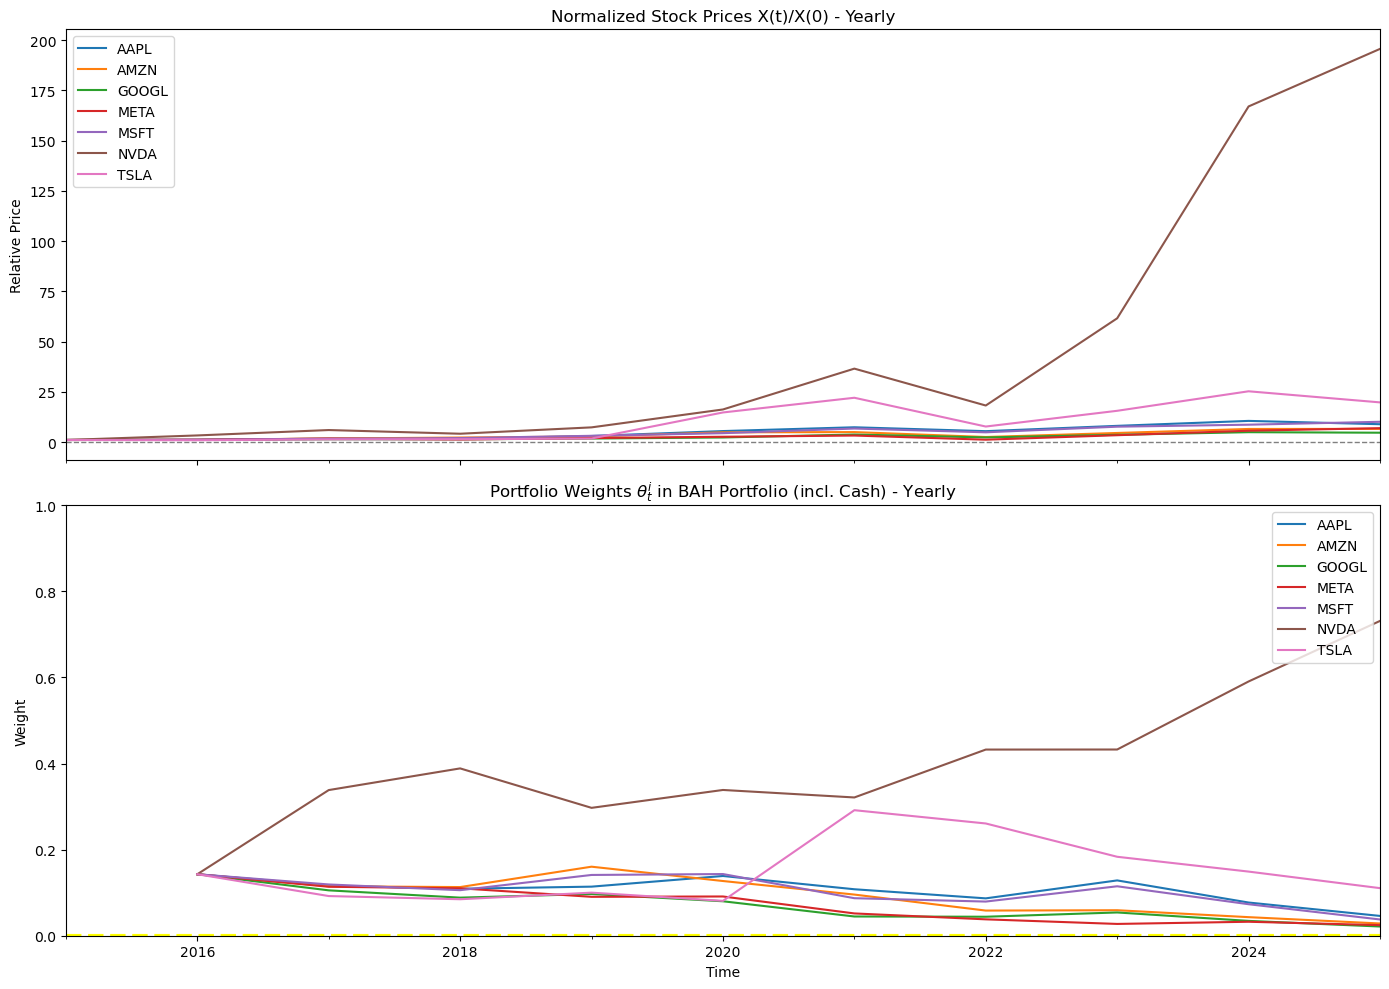

In [13]:
# === 10. Plot of theta time series against individual stock prices ===

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 10), sharex=True)

# Top plot: normalized stock prices
normalized.plot(ax=ax1)
ax1.axhline(0, color='gray', linestyle='--', linewidth=1)  
ax1.set_title("Normalized Stock Prices X(t)/X(0) - Yearly")
ax1.set_ylabel("Relative Price")
ax1.legend(loc="upper left")

# Bottom plot: theta values + cash position
theta.plot(ax=ax2)
ax2.axhline(0, color='yellow', linestyle='--', linewidth=3)  
ax2.set_title(r"Portfolio Weights $\theta_{t}^i$ in BAH Portfolio (incl. Cash) - Yearly")
ax2.set_ylabel("Weight")
ax2.set_ylim(0, 1)
ax2.legend(loc="upper right")
ax2.set_xlabel("Time")

plt.tight_layout()
plt.show()


In [14]:
# === 11. Compute MDD (maximal drawdown)
def compute_max_drawdown(series):
    running_max = series.cummax()
    drawdown = (series - running_max) / running_max
    max_drawdown = drawdown.min()
    return max_drawdown

In [15]:
#compute MDD of each portfolio
mdd_bah = compute_max_drawdown(bah_portfolio)
mdd_rebalanced = compute_max_drawdown(rebalanced_portfolio)
mdd_market = compute_max_drawdown(market_index)

In [16]:
print(f"Max Drawdown (BAH):       {mdd_bah:.2%}")
print(f"Max Drawdown (Rebalanced): {mdd_rebalanced:.2%}")
print(f"Max Drawdown (Market):     {mdd_market:.2%}")

Max Drawdown (BAH):       -50.28%
Max Drawdown (Rebalanced): -46.09%
Max Drawdown (Market):     -48.13%
